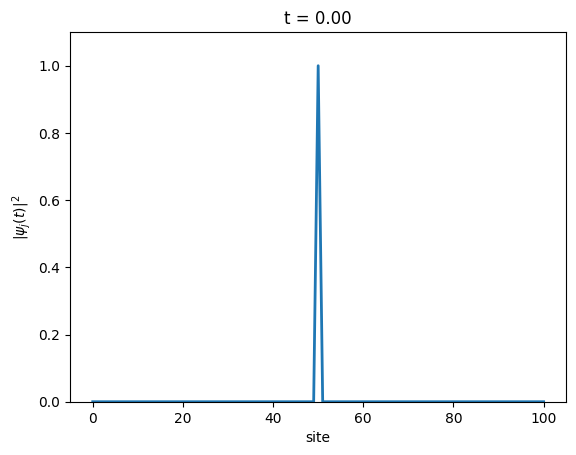

In [11]:
import numpy as np

import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation

from scipy.linalg import expm

from IPython.display import HTML

import matplotlib as mpl

mpl.rcParams["animation.html"] = "jshtml"


def build_hamiltonian(N, t_h=1.0, W=2.0, seed=None):

    rng = np.random.default_rng(seed)

    eps = rng.uniform(-W / 2, W / 2, size=N)

    H = np.diag(eps.astype(complex))

    for j in range(N - 1):

        H[j, j + 1] = -t_h

        H[j + 1, j] = -t_h

    return H, eps


def time_evolve(psi, U):

    return U @ psi


def sample_pair(N, alpha=2.0, rng=None):

    if rng is None:

        rng = np.random.default_rng()

    pairs = []

    weights = []

    for i in range(N):

        for j in range(i + 1, N):

            r = abs(i - j)

            pairs.append((i, j))

            weights.append(r ** (-alpha))

    weights = np.array(weights, dtype=float)

    weights /= weights.sum()

    idx = rng.choice(len(pairs), p=weights)

    return pairs[idx]


def measure_bond(psi, i, j, rng=None):
    """

    Projectively measure B_ij = |i><j| + |j><i|.

    Outcomes:

      + : symmetric state (|i> + |j>)/sqrt(2)

      - : antisymmetric state (|i> - |j>)/sqrt(2)

      0 : everything outside span{|i>, |j>}

    """

    if rng is None:

        rng = np.random.default_rng()

    a, b = psi[i], psi[j]

    p_plus = 0.5 * abs(a + b) ** 2

    p_minus = 0.5 * abs(a - b) ** 2

    p_zero = max(0.0, 1.0 - abs(a) ** 2 - abs(b) ** 2)

    probs = np.array([p_plus, p_minus, p_zero], dtype=float)

    probs /= probs.sum()

    outcome = rng.choice(["+", "-", "0"], p=probs)

    new_psi = np.zeros_like(psi)

    if outcome == "+":

        amp = 0.5 * (a + b)

        new_psi[i] = amp

        new_psi[j] = amp

    elif outcome == "-":

        amp_i = 0.5 * (a - b)

        new_psi[i] = amp_i

        new_psi[j] = -amp_i

    else:

        new_psi[:] = psi

        new_psi[i] = 0.0

        new_psi[j] = 0.0

    norm = np.linalg.norm(new_psi)

    if norm > 1e-14:

        new_psi /= norm

    else:

        new_psi = psi.copy()

    return new_psi, outcome, (i, j), probs


def ipr(psi):

    p = np.abs(psi) ** 2

    return np.sum(p**2)


def run_trajectory(
    N=101,
    t_h=1.0,
    W=4.0,
    dt=0.1,
    steps=300,
    alpha=2.0,
    measure_every=1,
    seed=0,
):

    rng = np.random.default_rng(seed)

    H, eps = build_hamiltonian(N, t_h=t_h, W=W, seed=seed)

    U = expm(-1j * H * dt)

    psi = np.zeros(N, dtype=complex)

    psi[N // 2] = 1.0

    psis = [psi.copy()]

    iprs = [ipr(psi)]

    outcomes = []

    for n in range(steps):

        psi = time_evolve(psi, U)

        if measure_every is not None and (n + 1) % measure_every == 0:

            i, j = sample_pair(N, alpha=alpha, rng=rng)

            psi, outcome, pair, probs = measure_bond(psi, i, j, rng=rng)

            outcomes.append((n + 1, outcome, pair, probs))

        psis.append(psi.copy())

        iprs.append(ipr(psi))

    return np.array(psis), np.array(iprs), eps, outcomes



if __name__ == "__main__":

    psis, iprs, eps, outcomes = run_trajectory(
        N=101,
        t_h=1.0,
        W=4.0,
        dt=0.1,
        steps=300,
        alpha=10,
        measure_every=1,
        seed=1,
    )

    anim = animate_probability(psis, dt=0.1)



In [12]:
HTML(anim.to_jshtml())

In [15]:
# clean spreading baseline

psis_clean, iprs_clean, eps_clean, _ = run_trajectory(

    N=101,

    t_h=1.0,

    W=0.0,

    dt=0.1,

    steps=300,

    alpha=1.0,

    measure_every=None,

    seed=1,

)

# disordered localization baseline

psis_dis, iprs_dis, eps_dis, _ = run_trajectory(

    N=101,

    t_h=1.0,

    W=100.0,

    dt=0.1,

    steps=300,

    alpha=1.0,

    measure_every=None,

    seed=2,

)

In [ ]:
anim_dis = animate_probability(psis_dis, dt=0.1)
HTML(anim_dis.to_jshtml())

In [ ]:
anim_clean = animate_probability(psis_clean, dt=0.1)
HTML(anim_clean.to_jshtml())